In [ ]:
import tensorflow as tf

from tensorflow.keras import layers,models

import matplotlib.pyplot as plt

import numpy as np

In [ ]:
(X_train,y_train),(X_test,y_test) = tf.keras.datasets.mnist.load_data()

print(X_train.shape)

print(y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)
(60000,)


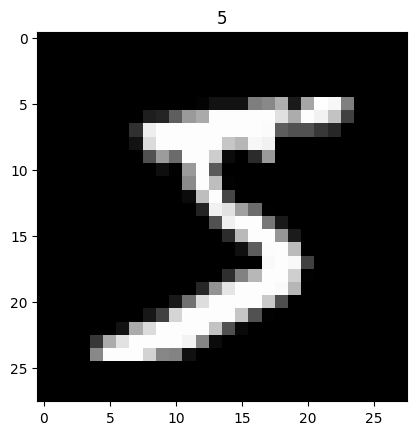

In [ ]:
# image example are

plt.imshow(X_train[0],cmap="gray")
plt.title(y_train[0])
plt.show()

In [ ]:
#  normalizing the image because image are having rgb pixels from 0 to 255 but in the neural network we are using only from 0 to 1

In [ ]:
X_train=X_train /255.0
X_test=X_test /255.0

In [ ]:
# because MNIST is grayscale.
X_train=X_train.reshape(-1,28,28,1)
X_test=X_test.reshape(-1,28,28,1)


In [ ]:
print(X_train.shape)

(60000, 28, 28, 1)


In [ ]:
# Input
#  |
# Conv2D
#  |
# MaxPooling
#  |
# Conv2D
#  |
# MaxPooling
#  |
# Flatten
#  |
# Dense
#  |
# Output(10 classes)

In [ ]:
model = models.Sequential([

    # First convolution layer
    layers.Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(28,28,1)
    ),

    layers.MaxPooling2D((2,2)),


    # Second convolution layer
    layers.Conv2D(
        64,
        (3,3),
        activation='relu'
    ),

    layers.MaxPooling2D((2,2)),


    # Convert 2D features into 1D
    layers.Flatten(),


    # Fully connected layer
    layers.Dense(
        128,
        activation='relu'
    ),


    # Output layer
    layers.Dense(
        10,
        activation='softmax'
    )
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy']
)


In [ ]:
history=model.fit(
    X_train,
    y_train,
    epochs=5,
    validation_data=(X_test,y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.9712 - loss: 0.0922 - val_accuracy: 0.9840 - val_loss: 0.0501
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 42s 22ms/step - accuracy: 0.9871 - loss: 0.0414 - val_accuracy: 0.9876 - val_loss: 0.0404
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.9905 - loss: 0.0286 - val_accuracy: 0.9861 - val_loss: 0.0432
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 35s 19ms/step - accuracy: 0.9934 - loss: 0.0206 - val_accuracy: 0.9916 - val_loss: 0.0287
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 35s 19ms/step - accuracy: 0.9948 - loss: 0.0154 - val_accuracy: 0.9908 - val_loss: 0.0298


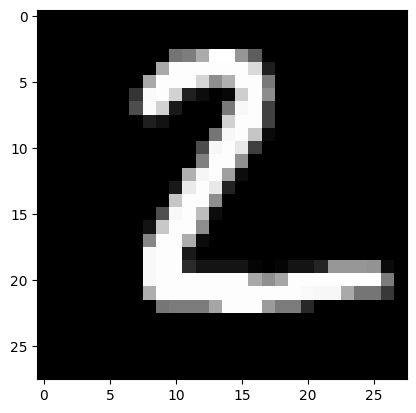

In [ ]:
image=X_test[1]

plt.imshow(image.reshape(28,28),cmap="gray")

plt.show()

In [ ]:
prediction = model.predict(image.reshape(1,28,28,1))
print(np.argmax(prediction))
# argmax find the highest number of index from the array and then print it

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
2


In [ ]:
model.save("mnist_cnn_model.keras")

In [ ]:
model = tf.keras.models.load_model("mnist_cnn_model.keras")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 10 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
